# 1. Loading the Datasets
## 1.1 Load Breast Cancer Wisconsin Dataset

In [201]:

import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer

# 1.1 Load the dataset
cancer = load_breast_cancer()

# 1.2 Create the feature DataFrame and target Series
X = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y = pd.Series(cancer.target, name="target")

# Display the first five rows
print("FIRST FIVE ROWS")
display(X.head())

# Dataset shape
print("DATASET SHAPE")
print("Samples:", X.shape[0])
print("Features:", X.shape[1])

# Feature names
print("\nFEATURE NAMES")
print(X.columns.tolist())

# Target labels and names
print("\nTARGET LABELS")
print(np.unique(y))

print("\nTARGET NAMES")
print(cancer.target_names)

# Class-label mapping
print("\nCLASS-LABEL MAPPING")
for label, name in enumerate(cancer.target_names):
    print(f"{label}: {name}")

# Samples in each class
print("\nCLASS DISTRIBUTION")
print(y.value_counts().sort_index())


FIRST FIVE ROWS


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


DATASET SHAPE
Samples: 569
Features: 30

FEATURE NAMES
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

TARGET LABELS
[0 1]

TARGET NAMES
['malignant' 'benign']

CLASS-LABEL MAPPING
0: malignant
1: benign

CLASS DISTRIBUTION
target
0    212
1    357
Name: count, dtype: int64


**Interpretation – Dataset Overview**
The Breast Cancer Wisconsin dataset includes 569 examples and 30 numerical features. The target variable has two classes: malignant (0) and benign (1). There are 212 malignant examples and 357 benign examples.

# 2. Dataset Quality Checks
## 2.1 Missing Values and Duplicates
## 2.2 Potential Outliers
## 2.3 Data Types

In [202]:

# 2.1 Missing Values and Duplicates
print("MISSING VALUES BY FEATURE")
print(X.isnull().sum().to_string())

print("\nTOTAL MISSING VALUES")
print(X.isnull().sum().sum())

print("\nDUPLICATE ROWS")
print(X.duplicated().sum())


# 2.2 Potential Outliers - IQR Method
print("\nPOTENTIAL OUTLIERS (IQR METHOD)")

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (X.lt(lower_bound) | X.gt(upper_bound))
outlier_counts = outliers.sum()

print(outlier_counts.to_string())
print("\nRows with at least one potential outlier:",
      outliers.any(axis=1).sum())


# 2.3 Data Types
print("\nFEATURE DATA TYPES")
print(X.dtypes.to_string())

print("\nNUMBER OF NUMERICAL FEATURES")
print(X.select_dtypes(include="number").shape[1])

print("\nNUMBER OF CATEGORICAL FEATURES")
print(X.select_dtypes(exclude="number").shape[1])


MISSING VALUES BY FEATURE
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0

TOTAL MISSING VALUES
0

DUPLICATE ROWS
0

POTENTIAL OUTLIERS (IQR METHOD)
mean radius                14

In [203]:
print("Total missing values:", X.isnull().sum().sum())
print("Duplicate rows:", X.duplicated().sum())
print("Rows with potential outliers:", outliers.any(axis=1).sum())

Total missing values: 0
Duplicate rows: 0
Rows with potential outliers: 171


**Interpretation – Dataset Quality Checks**

The dataset includes 30 numerical features and no categorical features. No missing values or duplicate rows detected. The IQR method identified 171 rows with at least one potential outlier. These observations  retained for another analysis because extreme values are not necessarily data errors.

# 3. Exploratory Data Analysis (EDA)
## 3.1 Descriptive Statistics

In [204]:

# 3.1 Descriptive Statistics

statistics = pd.DataFrame({
    "Mean": X.mean(),
    "Median": X.median(),
    "Minimum": X.min(),
    "Maximum": X.max(),
    "Standard Deviation": X.std(),
    "Q1": X.quantile(0.25),
    "Q3": X.quantile(0.75)
})

print("DESCRIPTIVE STATISTICS - BREAST CANCER")
display(statistics.round(4))


DESCRIPTIVE STATISTICS - BREAST CANCER


,Mean,Median,Minimum,Maximum,Standard Deviation,Q1,Q3
mean radius,14.1273,13.3700,6.9810,28.1100,3.5240,11.7000,15.7800
mean texture,19.2896,18.8400,9.7100,39.2800,4.3010,16.1700,21.8000
mean perimeter,91.9690,86.2400,43.7900,188.5000,24.2990,75.1700,104.1000
mean area,654.8891,551.1000,143.5000,2501.0000,351.9141,420.3000,782.7000
mean smoothness,0.0964,0.0959,0.0526,0.1634,0.0141,0.0864,0.1053
mean compactness,0.1043,0.0926,0.0194,0.3454,0.0528,0.0649,0.1304
mean concavity,0.0888,0.0615,0.0000,0.4268,0.0797,0.0296,0.1307
mean concave points,0.0489,0.0335,0.0000,0.2012,0.0388,0.0203,0.0740
mean symmetry,0.1812,0.1792,0.1060,0.3040,0.0274,0.1619,0.1957
mean fractal dimension,0.0628,0.0615,0.0500,0.0974,0.0071,0.0577,0.0661


## 3.2 Class Distribution and Correlations

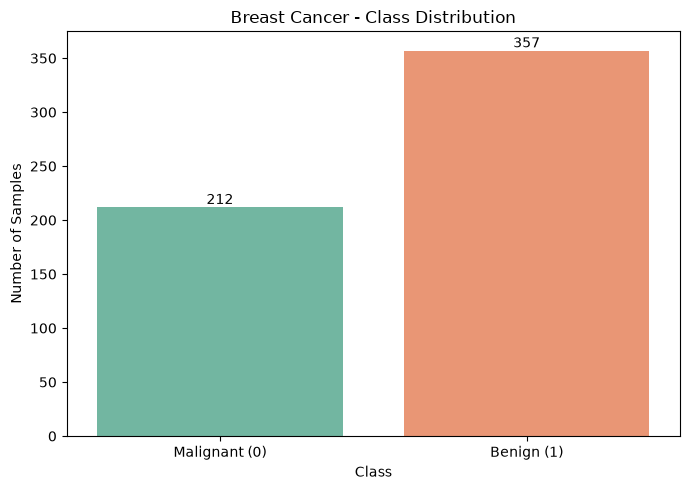

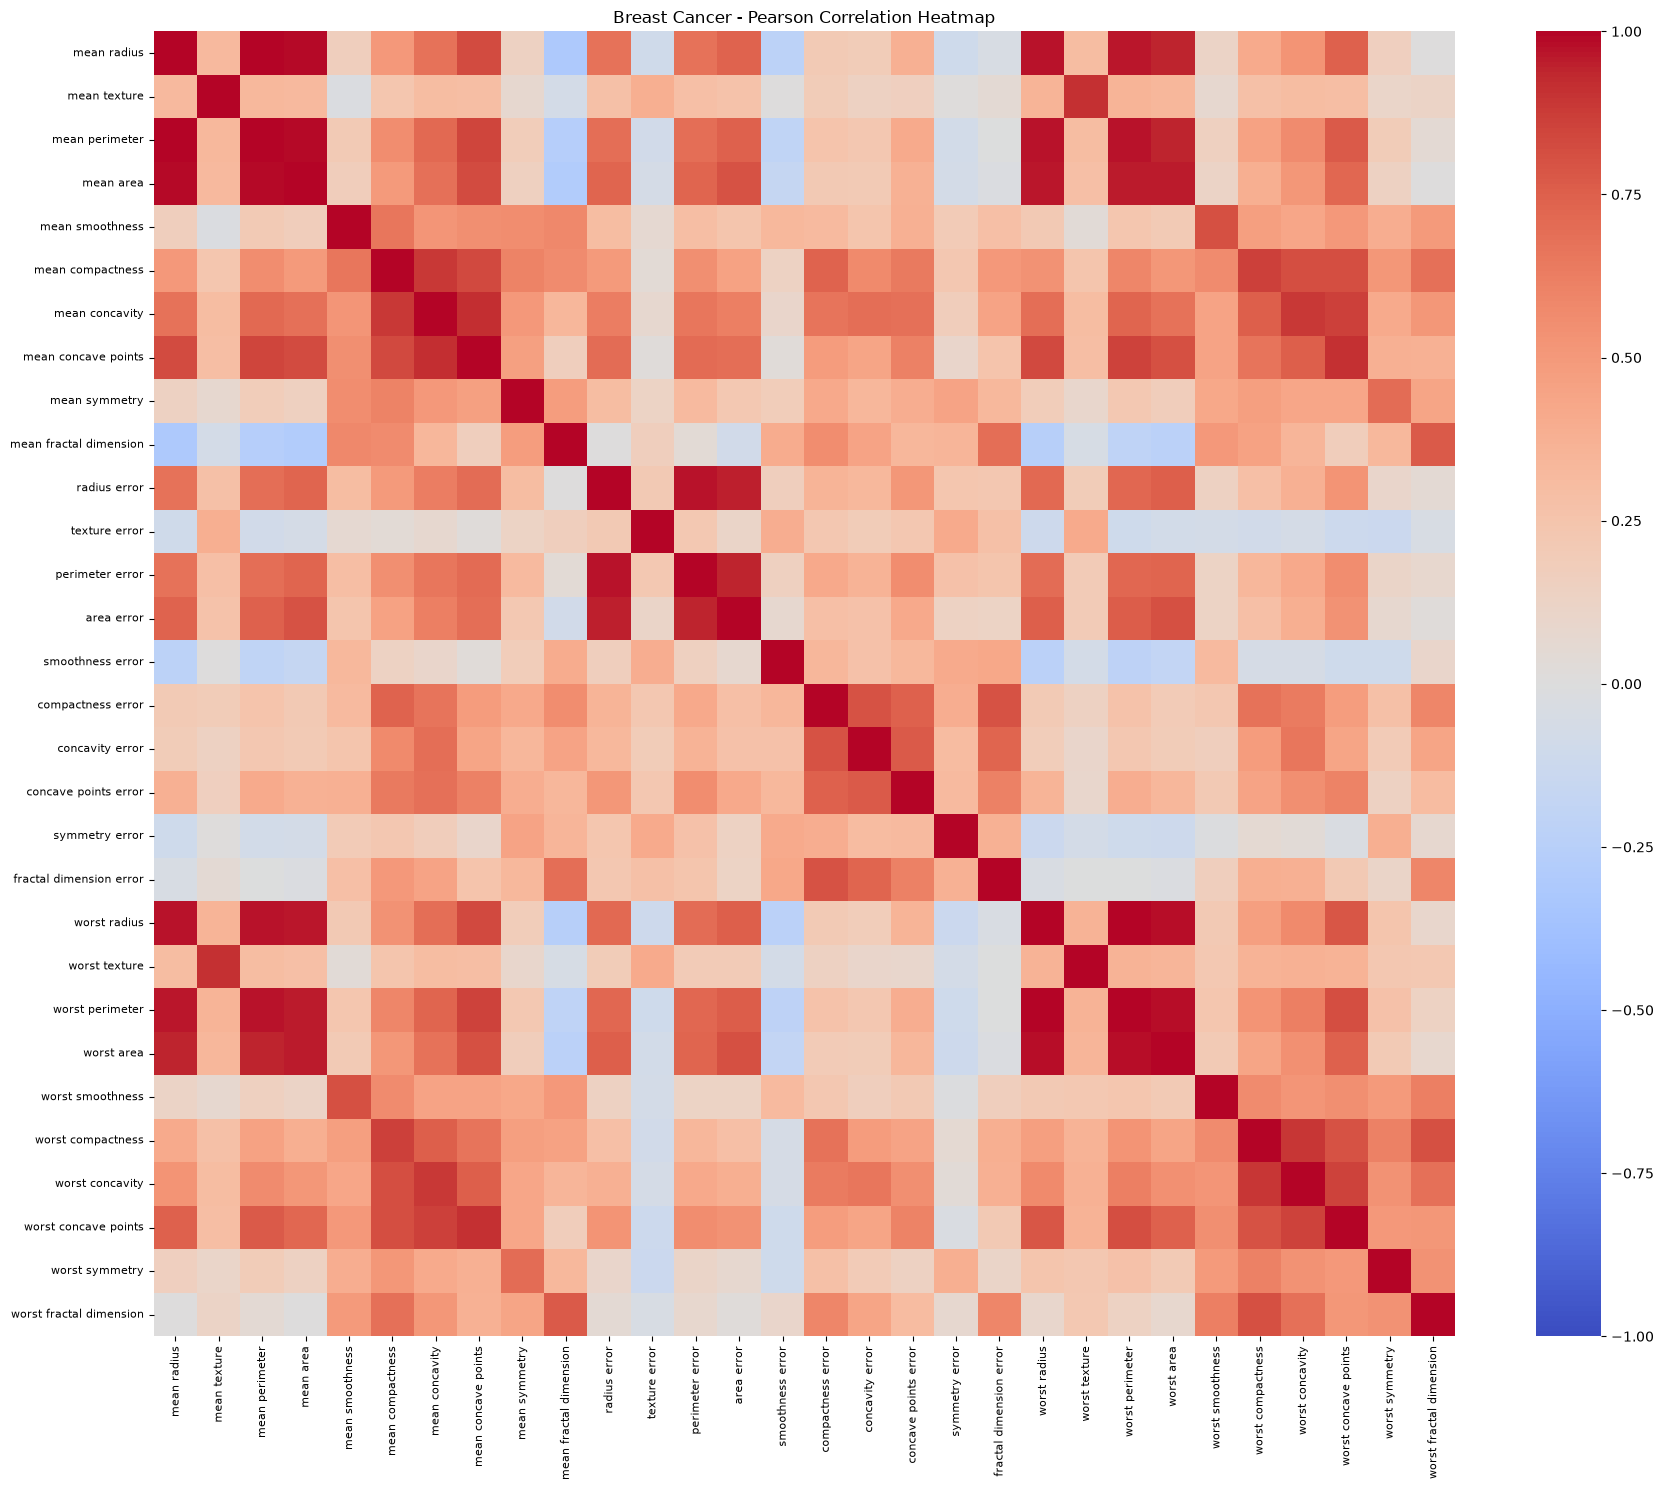

TOP 3 STRONGEST FEATURE CORRELATIONS
mean radius <-> mean perimeter: Correlation = 0.9979
worst radius <-> worst perimeter: Correlation = 0.9937
mean radius <-> mean area: Correlation = 0.9874


In [205]:

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Class Distribution
plt.figure(figsize=(7, 5))

class_counts = y.value_counts().sort_index()

sns.barplot(
    x=["Malignant (0)", "Benign (1)"],
    y=class_counts.values,
    hue=["Malignant (0)", "Benign (1)"],
    palette="Set2",
    legend=False
)

plt.title("Breast Cancer - Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")

for i, count in enumerate(class_counts.values):
    plt.text(i, count + 3, str(count), ha="center")

plt.tight_layout()
plt.savefig("figures/breast_cancer_class_distribution.png")
plt.show()


# 2. Pearson Correlation Heatmap
correlation_matrix = X.corr(method="pearson")

plt.figure(figsize=(18, 15))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Breast Cancer - Pearson Correlation Heatmap")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()
plt.savefig("figures/breast_cancer_correlation_heatmap.png")
plt.show()


# 3. Three Strongest Unique Feature Pairs
absolute_corr = correlation_matrix.abs()

upper_triangle = absolute_corr.where(
    np.triu(np.ones(absolute_corr.shape), k=1).astype(bool)
)

top_3_correlations = (
    upper_triangle.stack()
    .sort_values(ascending=False)
    .head(3)
)

print("TOP 3 STRONGEST FEATURE CORRELATIONS")

for (feature1, feature2), value in top_3_correlations.items():
    original_value = correlation_matrix.loc[feature1, feature2]

    print(
        f"{feature1} <-> {feature2}: "
        f"Correlation = {original_value:.4f}"
    )


## 3.3 Boxplots

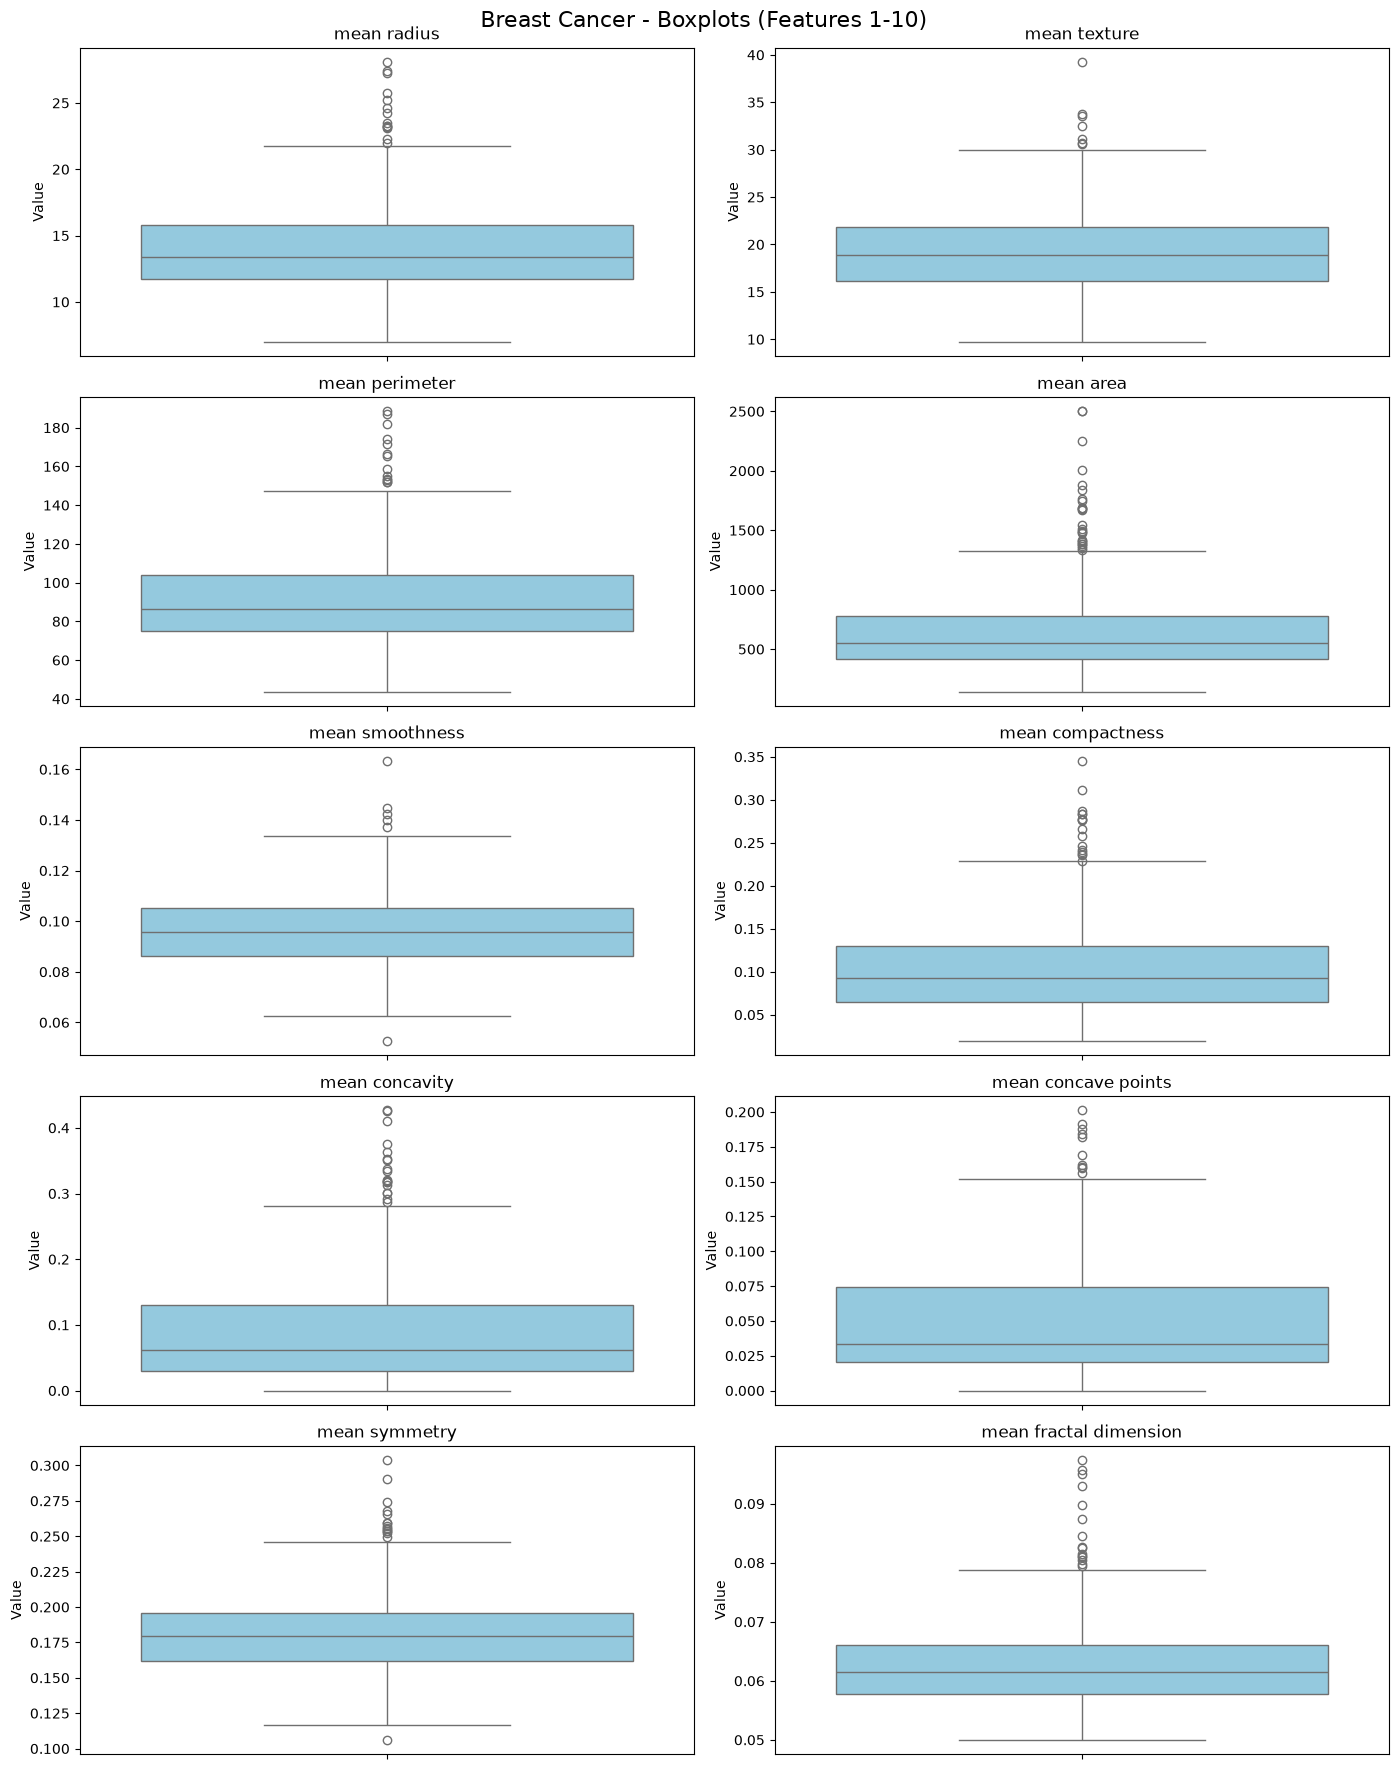

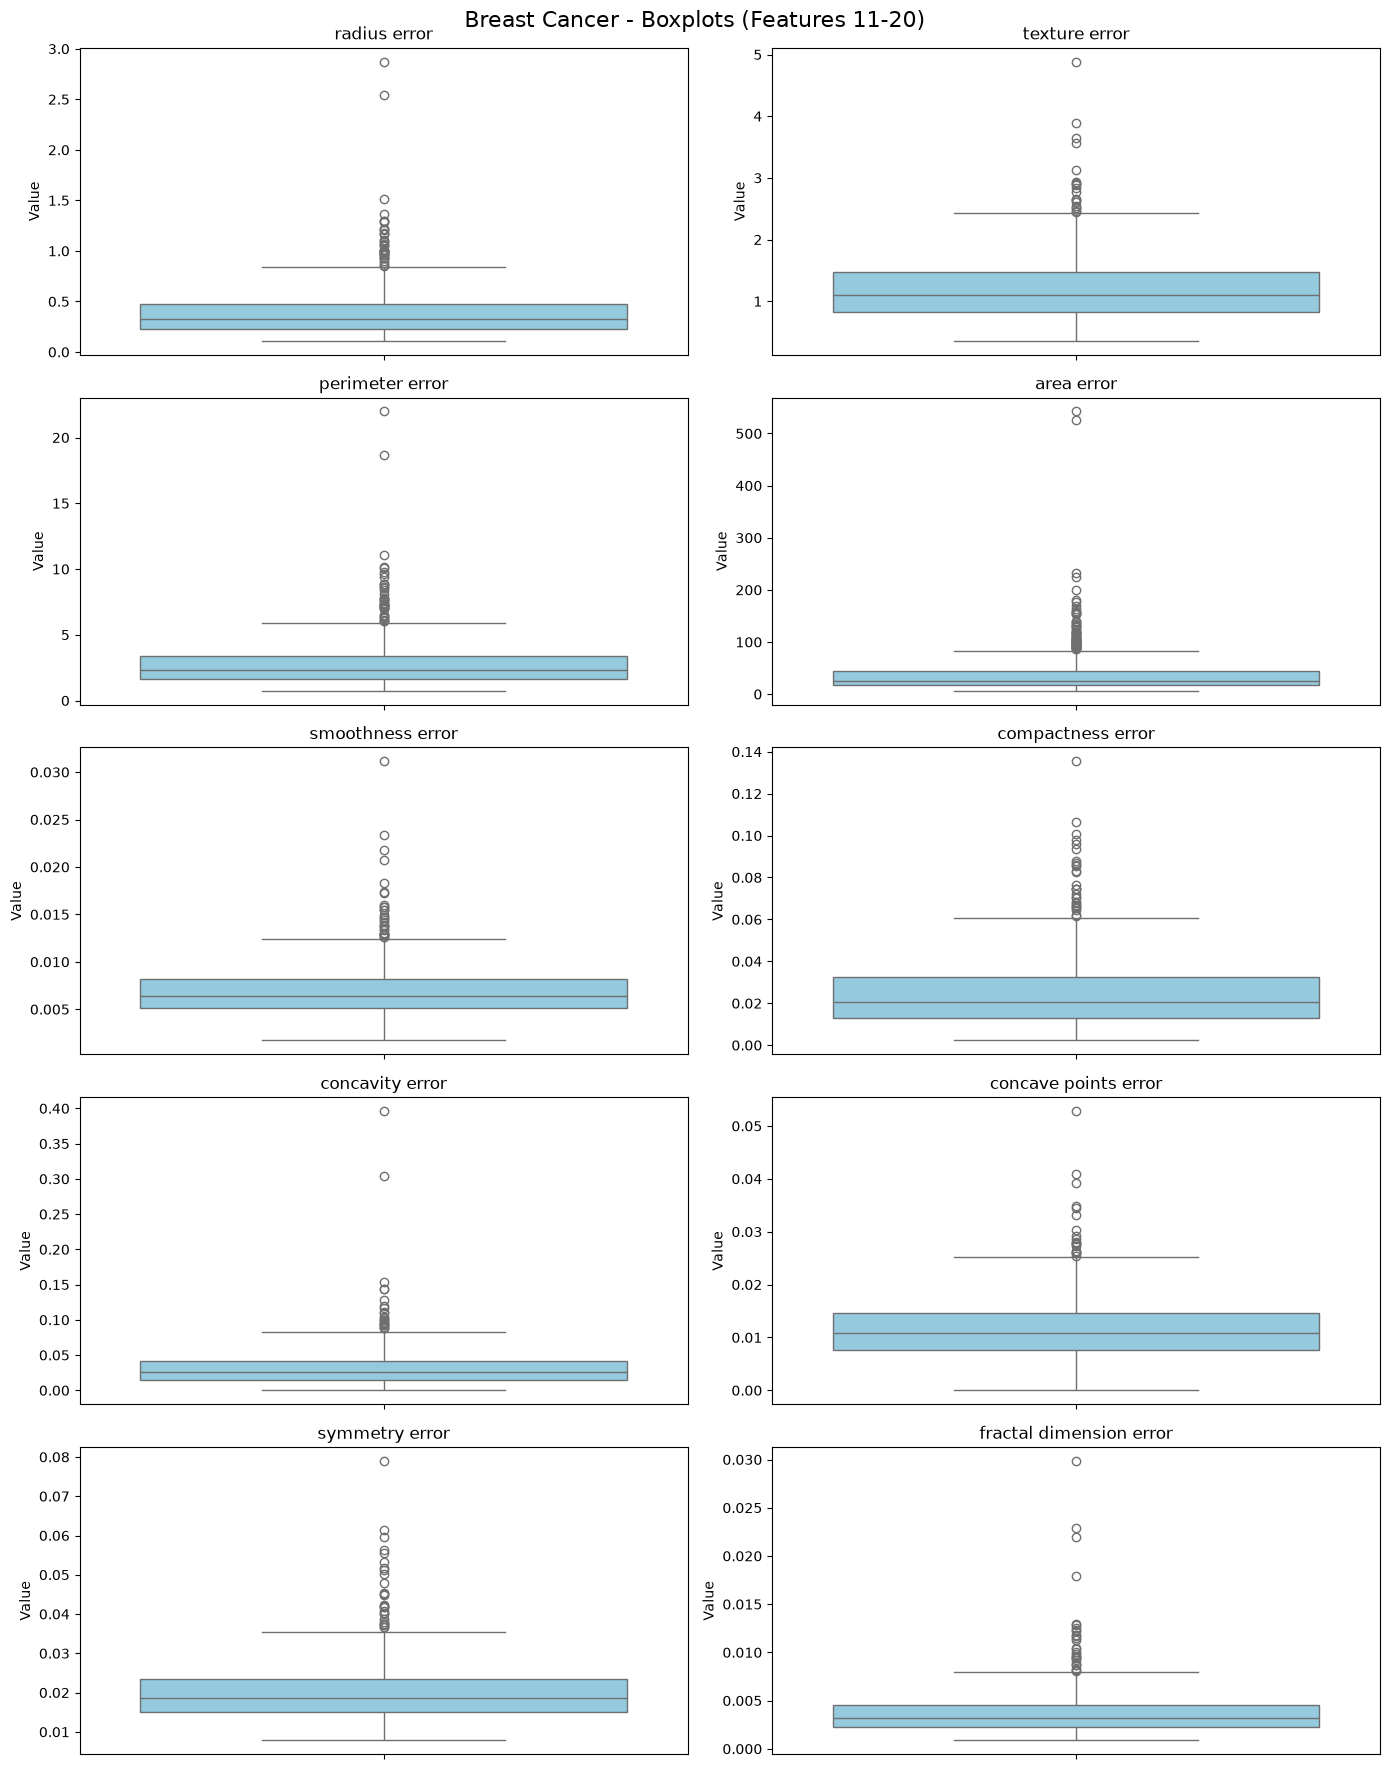

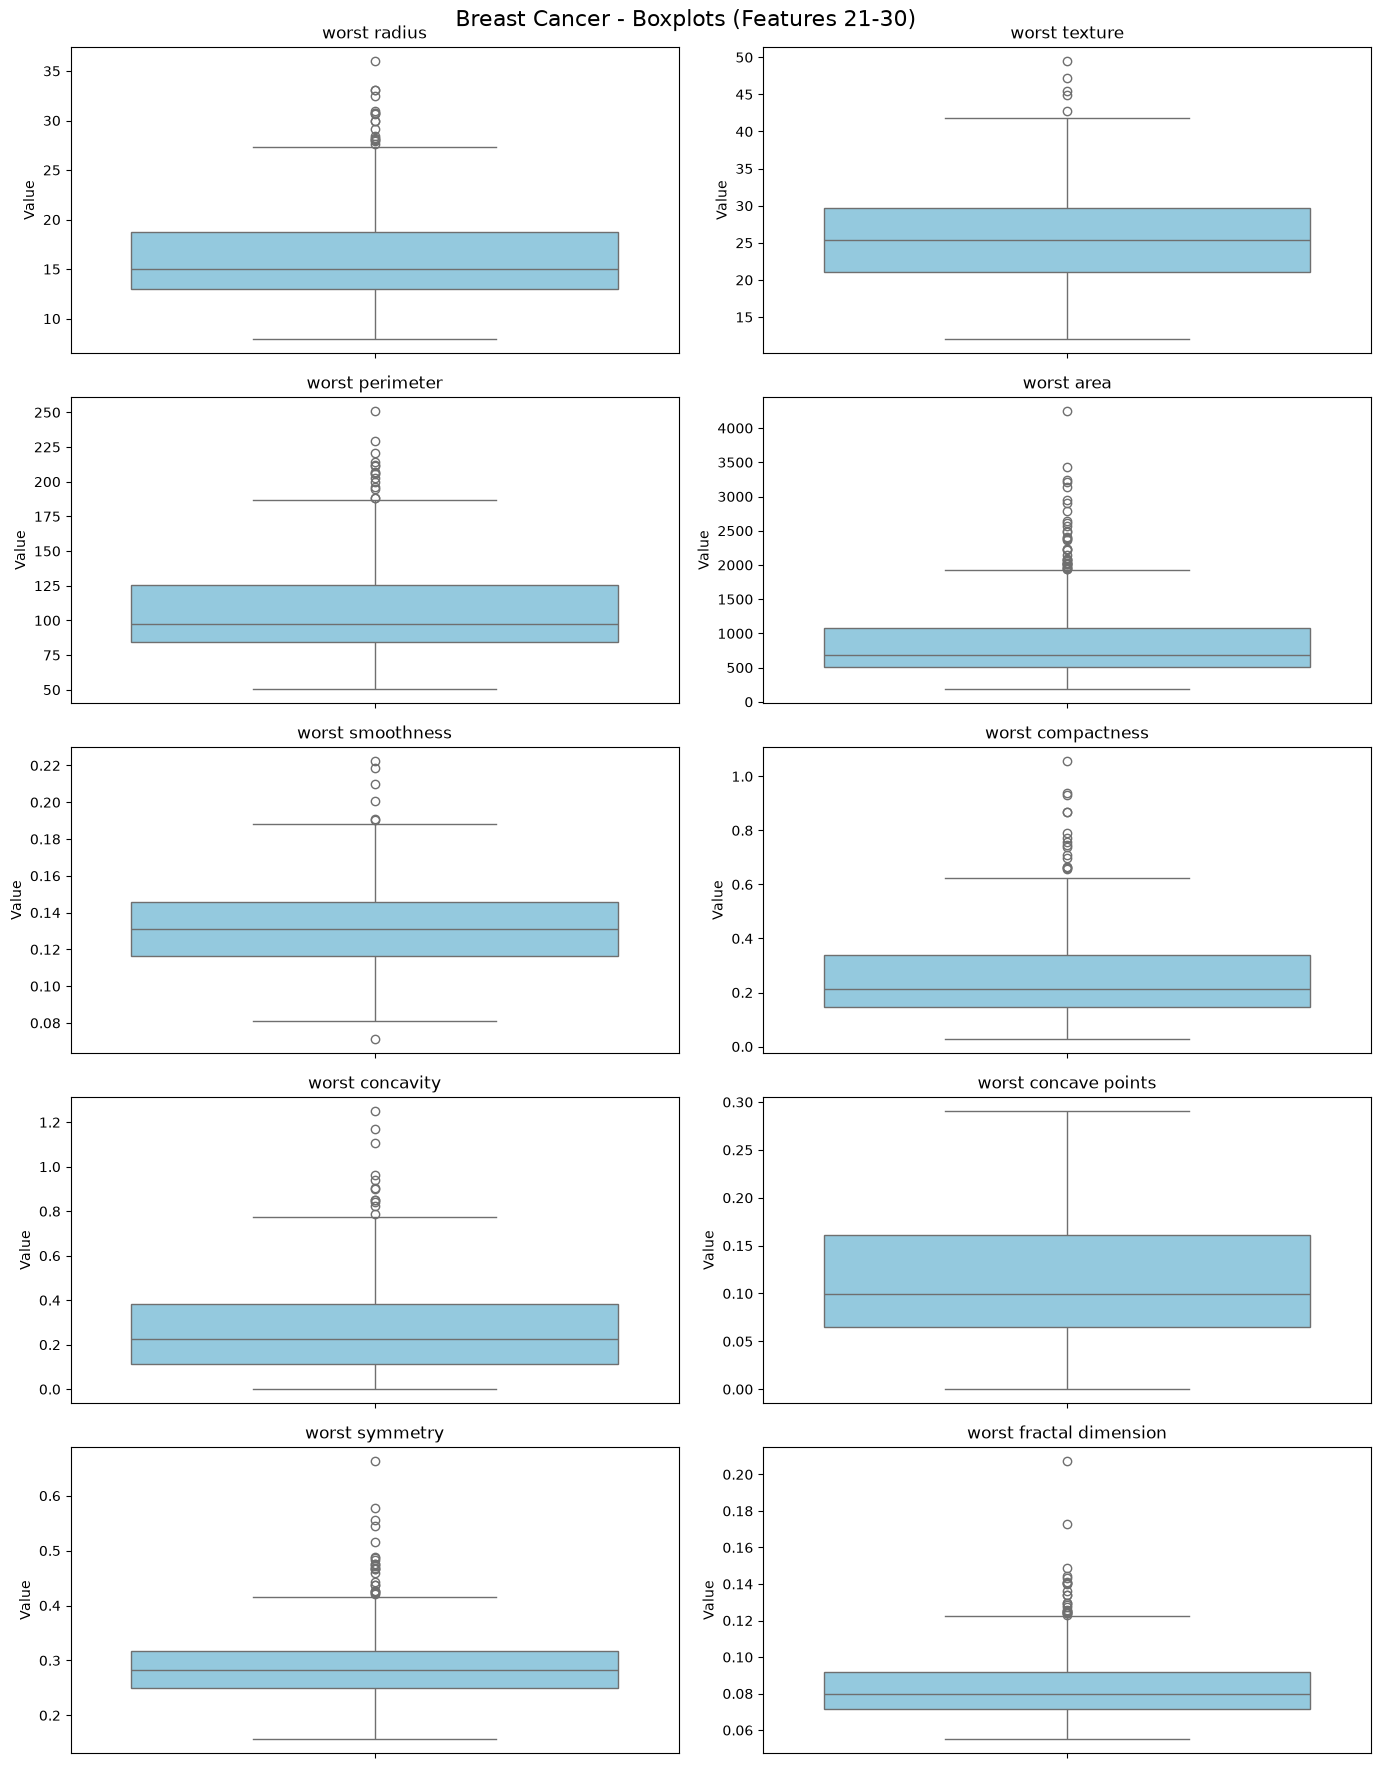

In [206]:
# 3.3 Boxplots for All Features

import os

os.makedirs("figures", exist_ok=True)

features = X.columns.tolist()

for i in range(0, len(features), 10):

    selected_features = features[i:i+10]

    fig, axes = plt.subplots(5, 2, figsize=(14, 18))
    axes = axes.flatten()

    for j, feature in enumerate(selected_features):

        sns.boxplot(
            y=X[feature],
            ax=axes[j],
            color="skyblue"
        )

        axes[j].set_title(feature)
        axes[j].set_ylabel("Value")

    plt.suptitle(
        f"Breast Cancer - Boxplots (Features {i+1}-{i+len(selected_features)})",
        fontsize=16
    )

    plt.tight_layout()

    plt.savefig(
        f"figures/breast_cancer_boxplots_{i//10+1}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

**Interpretation – Exploratory Data Analysis**

The Breast Cancer Wisconsin dataset contains 212 malignant and 357 benign samples. The benign class is more common.

The strongest positive correlation is between mean radius and mean perimeter (r = 0.9979). Worst radius and worst perimeter (r = 0.9937), and mean radius and mean area (r = 0.9874) also show strong positive correlations.

The boxplots show different feature . For example, mean area has much larger values than mean smoothness. Area error and worst area also includes a lot of high outliers. These observations  retained for another analysis.

Feature scaling is important because different value ranges can affect distance-based algorithms such as KNN and K-Means.

# 4. Splitting the Dataset
## 4.1 Fixed Test Set and Repeated Train/Validation Split
## 4.2 Verify the Splits

In [207]:

from sklearn.model_selection import train_test_split
import pandas as pd

# Three random seeds required by the assignment
SEEDS = [42, 52, 62]

# Step 1: Create the fixed 20% test set
X_remaining, X_test, y_remaining, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Step 2: Split the remaining 80% for each seed
splits = {}
split_summary = []

for seed in SEEDS:

    X_train, X_val, y_train, y_val = train_test_split(
        X_remaining,
        y_remaining,
        test_size=0.125,
        stratify=y_remaining,
        random_state=seed
    )

    splits[seed] = {
        "X_train": X_train,
        "X_val": X_val,
        "y_train": y_train,
        "y_val": y_val
    }

    # Verify that subsets do not overlap
    train_idx = set(X_train.index)
    val_idx = set(X_val.index)
    test_idx = set(X_test.index)

    assert train_idx.isdisjoint(val_idx)
    assert train_idx.isdisjoint(test_idx)
    assert val_idx.isdisjoint(test_idx)

    assert len(X_train) + len(X_val) + len(X_test) == len(X)

    # Store summary rows
    for subset_name, subset_y in [
        ("Train", y_train),
        ("Validation", y_val),
        ("Test", y_test)
    ]:
        split_summary.append({
            "Seed": seed,
            "Subset": subset_name,
            "Samples": len(subset_y),
            "Percentage": round(len(subset_y) / len(X) * 100, 2),
            "Malignant (0)": int((subset_y == 0).sum()),
            "Benign (1)": int((subset_y == 1).sum())
        })

# Create the required nine-row summary table
split_summary_df = pd.DataFrame(split_summary)

print("BREAST CANCER - SPLIT SUMMARY")
display(split_summary_df)

# Show original row indices for inspection
for seed in SEEDS:
    print(f"\nSEED {seed}")
    print("Train indices:", splits[seed]["X_train"].index.tolist())
    print("Validation indices:", splits[seed]["X_val"].index.tolist())
    print("Test indices:", X_test.index.tolist())

# Verify that the fixed test indices are unchanged
assert all(
    X_test.index.equals(X_test.index)
    for seed in SEEDS
)




BREAST CANCER - SPLIT SUMMARY


,Seed,Subset,Samples,Percentage,Malignant (0),Benign (1)
0,42,Train,398,69.95,149,249
1,42,Validation,57,10.02,21,36
2,42,Test,114,20.04,42,72
3,52,Train,398,69.95,149,249
4,52,Validation,57,10.02,21,36
5,52,Test,114,20.04,42,72
6,62,Train,398,69.95,149,249
7,62,Validation,57,10.02,21,36
8,62,Test,114,20.04,42,72



SEED 42
Train indices: [301, 390, 420, 356, 446, 56, 82, 221, 339, 364, 37, 263, 341, 210, 514, 234, 99, 533, 482, 69, 484, 192, 392, 81, 245, 529, 91, 35, 456, 351, 79, 272, 270, 177, 469, 46, 163, 181, 107, 108, 332, 48, 262, 362, 379, 531, 146, 382, 562, 325, 98, 377, 400, 532, 539, 500, 100, 438, 460, 274, 419, 207, 441, 172, 411, 315, 347, 144, 306, 148, 233, 57, 36, 372, 409, 282, 287, 416, 68, 369, 61, 478, 512, 278, 143, 265, 165, 474, 561, 413, 67, 432, 42, 236, 54, 374, 548, 401, 201, 458, 162, 159, 32, 171, 337, 229, 312, 277, 322, 304, 290, 436, 241, 106, 249, 348, 136, 334, 178, 2, 398, 368, 47, 503, 62, 554, 116, 546, 202, 89, 297, 124, 253, 521, 330, 5, 251, 538, 166, 182, 268, 195, 138, 19, 470, 286, 226, 414, 188, 59, 218, 510, 345, 430, 208, 8, 3, 160, 403, 149, 133, 65, 294, 371, 209, 509, 404, 179, 485, 357, 219, 547, 141, 556, 97, 388, 300, 25, 53, 448, 412, 565, 130, 225, 255, 118, 499, 493, 437, 303, 497, 216, 384, 506, 389, 536, 222, 324, 492, 175, 11, 299, 545

**Interpretation – Splitting the Dataset**

The dataset was split into 70% training, 10% validation, and 20% testing.

We used three seeds: 42, 52, and 62. The test set was the same for all seeds.

We used stratified splitting to keep similar class ratios.

Training data was used to train models. Validation data was used to choose the best model. Test data was used to check the final result.

# 5. Data Preprocessing and Scaling
## 5.1 Missing Values
## 5.2 Selected Scaler
## 5.3 Training-Only Scaling

In [208]:

from sklearn.preprocessing import StandardScaler

# Check whether imputation is needed
print("TOTAL MISSING VALUES:", X.isnull().sum().sum())

if X.isnull().sum().sum() == 0:
    print("No missing values. Imputation is not required.")
else:
    print("Missing values detected. Training-only imputation is required.")

# Store scaled datasets and fitted scalers separately
scaled_splits = {}
scalers = {}

for seed in SEEDS:

    X_train = splits[seed]["X_train"]
    X_val = splits[seed]["X_val"]

    # Create a new scaler for each seed
    scaler = StandardScaler()

    # Fit only on training data
    X_train_scaled_array = scaler.fit_transform(X_train)

    # Transform validation data without refitting
    X_val_scaled_array = scaler.transform(X_val)

    # Preserve feature names and original row indices
    X_train_scaled = pd.DataFrame(
        X_train_scaled_array,
        columns=X_train.columns,
        index=X_train.index
    )

    X_val_scaled = pd.DataFrame(
        X_val_scaled_array,
        columns=X_val.columns,
        index=X_val.index
    )

    scalers[seed] = scaler

    scaled_splits[seed] = {
        "X_train_scaled": X_train_scaled,
        "X_val_scaled": X_val_scaled
    }

    print(f"Seed {seed}: Scaling completed.")

# Transform fixed test set with seed-42 scaler only
X_test_scaled = pd.DataFrame(
    scalers[42].transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Show before/after scaling only for seed 42
print("\nBEFORE SCALING - SEED 42")
display(splits[42]["X_train"].head())

print("\nAFTER SCALING - SEED 42")
display(scaled_splits[42]["X_train_scaled"].head())




TOTAL MISSING VALUES: 0
No missing values. Imputation is not required.
Seed 42: Scaling completed.
Seed 52: Scaling completed.
Seed 62: Scaling completed.

BEFORE SCALING - SEED 42


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,12.46,19.89,80.43,471.3,0.08451,0.10140,0.06830,0.03099,0.1781,0.06249,...,13.46,23.07,88.13,551.3,0.1050,0.2158,0.19040,0.07625,0.2685,0.07764
390,10.26,12.22,65.75,321.6,0.09996,0.07542,0.01923,0.01968,0.1800,0.06569,...,11.38,15.65,73.23,394.5,0.1343,0.1650,0.08615,0.06696,0.2937,0.07722
420,11.57,19.04,74.20,409.7,0.08546,0.07722,0.05485,0.01428,0.2031,0.06267,...,13.07,26.98,86.43,520.5,0.1249,0.1937,0.25600,0.06664,0.3035,0.08284
356,13.05,18.59,85.09,512.0,0.10820,0.13040,0.09603,0.05603,0.2035,0.06501,...,14.19,24.85,94.22,591.2,0.1343,0.2658,0.25730,0.12580,0.3113,0.08317
446,17.75,28.03,117.30,981.6,0.09997,0.13140,0.16980,0.08293,0.1713,0.05916,...,21.53,38.54,145.40,1437.0,0.1401,0.3762,0.63990,0.19700,0.2972,0.09075



AFTER SCALING - SEED 42


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,-0.464835,0.176821,-0.467521,-0.518737,-0.883771,-0.073305,-0.280632,-0.466742,-0.076775,-0.069315,...,-0.573411,-0.379056,-0.561075,-0.578285,-1.226438,-0.259443,-0.416465,-0.584935,-0.339632,-0.358158
390,-1.084133,-1.553003,-1.065325,-0.944480,0.250510,-0.553959,-0.868776,-0.752546,-0.009649,0.375173,...,-1.001136,-1.547363,-1.000394,-0.854885,0.069897,-0.573037,-0.892843,-0.723620,0.046080,-0.381146
420,-0.715369,-0.014881,-0.721221,-0.693926,-0.814026,-0.520657,-0.441841,-0.889004,0.806456,-0.044313,...,-0.653609,0.236588,-0.611199,-0.632617,-0.345992,-0.395869,-0.116701,-0.728397,0.196078,-0.073535
356,-0.298750,-0.116370,-0.277754,-0.402988,0.855460,0.463223,0.051734,0.166020,0.820588,0.280719,...,-0.423295,-0.098788,-0.381515,-0.507900,0.069897,0.049213,-0.110760,0.154767,0.315465,-0.055472
446,1.024295,2.012644,1.033914,0.932543,0.251244,0.481724,0.935926,0.845785,-0.317013,-0.531861,...,1.086082,2.056753,1.127502,0.984118,0.326509,0.730725,1.637560,1.217669,0.099650,0.359420


**Interpretation – Data Preprocessing and Scaling**

There were no missing values, so we did not need to fill any data.

We used StandardScaler for all three seeds. It changes the feature values to a similar scale.

The scaler learned only from the training data. We used the same scaler to change the validation data.

For the final test, we used the scaler from seed 42. This helps prevent data leakage.

# 6. Preparing the Two Data Representations

In [209]:

# 6. Preparing the Two Data Representations

representations = {}

for seed in SEEDS:

    representations[seed] = {

        "unscaled": {
            "X_train": splits[seed]["X_train"],
            "X_val": splits[seed]["X_val"],
            "y_train": splits[seed]["y_train"],
            "y_val": splits[seed]["y_val"]
        },

        "scaled": {
            "X_train": scaled_splits[seed]["X_train_scaled"],
            "X_val": scaled_splits[seed]["X_val_scaled"],
            "y_train": splits[seed]["y_train"],
            "y_val": splits[seed]["y_val"]
        }
    }

# Verify that both representations use the same samples
for seed in SEEDS:

    unscaled = representations[seed]["unscaled"]
    scaled = representations[seed]["scaled"]

    assert unscaled["X_train"].index.equals(
        scaled["X_train"].index
    )

    assert unscaled["X_val"].index.equals(
        scaled["X_val"].index
    )

    assert unscaled["X_train"].shape == scaled["X_train"].shape
    assert unscaled["X_val"].shape == scaled["X_val"].shape

    print(f"Seed {seed}: Both representations verified.")




Seed 42: Both representations verified.
Seed 52: Both representations verified.
Seed 62: Both representations verified.


**Interpretation – Two Data Representations**

We prepared two types of data: scaled and unscaled.

Unscaled data has the original feature values. Scaled data has values changed by StandardScaler.

Both types use the same training and validation samples. This helps us compare the effect of scaling on the models.

# 7. Training the Classification Models
## 7.1 Required Experiments
## 7.2 Recording the Experiments

# 8. Measuring Validation Performance
## 8.1 Required Metrics

In [210]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import sklearn
import numpy as np
import pandas as pd

# Required parameter settings
tree_depths = [2, 3, 5, 10, None]
knn_neighbors = [1, 3, 5, 7, 11]

# Store experiment results and fitted models
classifier_results = []
fitted_models = {}

# Breast Cancer: original class 0 is malignant
def calculate_metrics(y_true, y_pred, probabilities, classes):

    malignant_column = np.where(classes == 0)[0][0]

    # Convert original class 0 to positive class for ROC-AUC
    y_binary = (np.asarray(y_true) == 0).astype(int)

    return {
        "accuracy": accuracy_score(y_true, y_pred),

        "macro_precision": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

        "macro_recall": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

        "macro_f1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

        "roc_auc": roc_auc_score(
            y_binary,
            probabilities[:, malignant_column]
        )
    }


# Train models for all three seeds
for seed in SEEDS:

    for representation in ["unscaled", "scaled"]:

        data = representations[seed][representation]

        X_train = data["X_train"]
        X_val = data["X_val"]
        y_train = data["y_train"]
        y_val = data["y_val"]

        # Prepare required configurations
        configurations = []

        for depth in tree_depths:
            configurations.append((
                "decision_tree",
                f"depth{depth}",
                DecisionTreeClassifier(
                    max_depth=depth,
                    random_state=seed
                )
            ))

        for k in knn_neighbors:
            configurations.append((
                "knn",
                f"k{k}",
                KNeighborsClassifier(
                    n_neighbors=k,
                    weights="uniform",
                    metric="euclidean"
                )
            ))

        configurations.append((
            "gaussian_nb",
            "default",
            GaussianNB()
        ))

        # Fit and evaluate each configuration
        for algorithm, parameter, model in configurations:

            experiment_id = (
                f"breast_cancer_{algorithm}_"
                f"{representation}_{parameter}_s{seed}"
            )

            # Training data only
            model.fit(X_train, y_train)

            train_predictions = model.predict(X_train)
            val_predictions = model.predict(X_val)

            val_probabilities = model.predict_proba(X_val)

            # Training metrics
            train_accuracy = accuracy_score(
                y_train, train_predictions
            )

            train_macro_f1 = f1_score(
                y_train,
                train_predictions,
                average="macro",
                zero_division=0
            )

            # Validation metrics
            validation_metrics = calculate_metrics(
                y_val,
                val_predictions,
                val_probabilities,
                model.classes_
            )

            classifier_results.append({
                "dataset": "breast_cancer",
                "experiment_id": experiment_id,
                "seed": seed,
                "algorithm": algorithm,
                "representation": representation,
                "parameter": parameter,
                "train_accuracy": train_accuracy,
                "train_macro_f1": train_macro_f1,
                "val_accuracy": validation_metrics["accuracy"],
                "val_macro_precision": validation_metrics["macro_precision"],
                "val_macro_recall": validation_metrics["macro_recall"],
                "val_macro_f1": validation_metrics["macro_f1"],
                "val_roc_auc": validation_metrics["roc_auc"]
            })

            # Retain fitted models, including seed 42
            fitted_models[experiment_id] = model

# Create results table
classifier_runs_df = pd.DataFrame(classifier_results)

print("BREAST CANCER - CLASSIFIER RUNS")
display(classifier_runs_df)

print("\nTOTAL CLASSIFIER RUNS:", len(classifier_runs_df))

assert len(classifier_runs_df) == 66
assert classifier_runs_df["experiment_id"].is_unique



print("\nSCIKIT-LEARN VERSION:", sklearn.__version__)
print("NUMPY VERSION:", np.__version__)
print("PANDAS VERSION:", pd.__version__)


BREAST CANCER - CLASSIFIER RUNS


,dataset,experiment_id,seed,algorithm,representation,parameter,train_accuracy,train_macro_f1,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_roc_auc
0,breast_cancer,breast_cancer_decision_tree_unscaled_depth2_s42,42,decision_tree,unscaled,depth2,0.954774,0.951595,0.894737,0.894737,0.876984,0.884459,0.875661
1,breast_cancer,breast_cancer_decision_tree_unscaled_depth3_s42,42,decision_tree,unscaled,depth3,0.972362,0.970031,0.894737,0.894737,0.876984,0.884459,0.919312
2,breast_cancer,breast_cancer_decision_tree_unscaled_depth5_s42,42,decision_tree,unscaled,depth5,0.997487,0.997314,0.912281,0.909459,0.900794,0.904778,0.921296
3,breast_cancer,breast_cancer_decision_tree_unscaled_depth10_s42,42,decision_tree,unscaled,depth10,1.000000,1.000000,0.929825,0.924603,0.924603,0.924603,0.924603
4,breast_cancer,breast_cancer_decision_tree_unscaled_depthNone...,42,decision_tree,unscaled,depthNone,1.000000,1.000000,0.929825,0.924603,0.924603,0.924603,0.924603
...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,breast_cancer,breast_cancer_knn_scaled_k3_s62,62,knn,scaled,k3,0.984925,0.983820,0.982456,0.986486,0.976190,0.980956,0.997354
62,breast_cancer,breast_cancer_knn_scaled_k5_s62,62,knn,scaled,k5,0.972362,0.970294,0.982456,0.986486,0.976190,0.980956,0.999339
63,breast_cancer,breast_cancer_knn_scaled_k7_s62,62,knn,scaled,k7,0.969849,0.967453,1.000000,1.000000,1.000000,1.000000,1.000000
64,breast_cancer,breast_cancer_knn_scaled_k11_s62,62,knn,scaled,k11,0.972362,0.970209,1.000000,1.000000,1.000000,1.000000,1.000000



TOTAL CLASSIFIER RUNS: 66

SCIKIT-LEARN VERSION: 1.9.1
NUMPY VERSION: 2.5.4
PANDAS VERSION: 3.1.1


## 8.2 Comparison Tables and Model Selection

In [211]:

# 8.2 Comparison Tables and Model Selection

import os

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)

# Metrics to summarize across the three seeds
metric_columns = [
    "train_accuracy",
    "train_macro_f1",
    "val_accuracy",
    "val_macro_precision",
    "val_macro_recall",
    "val_macro_f1",
    "val_roc_auc"
]

group_columns = [
    "dataset",
    "algorithm",
    "representation",
    "parameter"
]

# Calculate mean and sample standard deviation
classifier_summary_df = (
    classifier_runs_df
    .groupby(group_columns, as_index=False)
    [metric_columns]
    .agg(["mean", "std"])
)

# Flatten the column names
classifier_summary_df.columns = [
    "_".join(col).strip("_")
    if isinstance(col, tuple) else col
    for col in classifier_summary_df.columns
]

# Create alphabetical configuration ID for tie-breaking
classifier_summary_df["configuration_id"] = (
    classifier_summary_df["dataset"] + "_" +
    classifier_summary_df["algorithm"] + "_" +
    classifier_summary_df["representation"] + "_" +
    classifier_summary_df["parameter"]
)

# Sort using the required selection rules
classifier_summary_df = classifier_summary_df.sort_values(
    by=[
        "val_macro_f1_mean",
        "val_accuracy_mean",
        "val_macro_f1_std",
        "configuration_id"
    ],
    ascending=[False, False, True, True]
).reset_index(drop=True)

print("BREAST CANCER - CLASSIFIER SUMMARY")
display(classifier_summary_df.round(4))

print("\nNUMBER OF CONFIGURATIONS:", len(classifier_summary_df))

assert len(classifier_summary_df) == 22

# Freeze the selected configuration
best_configuration = classifier_summary_df.iloc[0].copy()

print("\nSELECTED CONFIGURATION")
print("Algorithm:", best_configuration["algorithm"])
print("Representation:", best_configuration["representation"])
print("Parameter:", best_configuration["parameter"])
print("Mean Validation Macro-F1:",
      round(best_configuration["val_macro_f1_mean"], 4))
print("Validation Macro-F1 Std:",
      round(best_configuration["val_macro_f1_std"], 4))

# Save the Breast Cancer results separately for now
classifier_runs_df.to_csv(
    "results/breast_cancer_classifier_runs.csv",
    index=False
)

classifier_summary_df.to_csv(
    "results/breast_cancer_classifier_summary.csv",
    index=False
)



BREAST CANCER - CLASSIFIER SUMMARY


,dataset,algorithm,representation,parameter,train_accuracy_mean,train_accuracy_std,train_macro_f1_mean,train_macro_f1_std,val_accuracy_mean,val_accuracy_std,val_macro_precision_mean,val_macro_precision_std,val_macro_recall_mean,val_macro_recall_std,val_macro_f1_mean,val_macro_f1_std,val_roc_auc_mean,val_roc_auc_std,configuration_id
0,breast_cancer,knn,scaled,k7,0.9724,0.0025,0.9702,0.0028,0.9708,0.0268,0.9784,0.0197,0.9603,0.0364,0.9677,0.0297,0.9782,0.0194,breast_cancer_knn_scaled_k7
1,breast_cancer,knn,scaled,k11,0.9715,0.0015,0.9694,0.0015,0.9649,0.0351,0.9746,0.0250,0.9524,0.0476,0.9608,0.0395,0.9945,0.0048,breast_cancer_knn_scaled_k11
2,breast_cancer,knn,scaled,k3,0.9807,0.0038,0.9793,0.0041,0.9591,0.0203,0.9699,0.0144,0.9444,0.0275,0.9547,0.0228,0.9793,0.0162,breast_cancer_knn_scaled_k3
3,breast_cancer,knn,scaled,k5,0.9740,0.0029,0.9721,0.0032,0.9591,0.0203,0.9699,0.0144,0.9444,0.0275,0.9547,0.0228,0.9795,0.0174,breast_cancer_knn_scaled_k5
4,breast_cancer,knn,scaled,k1,1.0000,0.0000,1.0000,0.0000,0.9415,0.0203,0.9410,0.0283,0.9339,0.0160,0.9369,0.0213,0.9339,0.0160,breast_cancer_knn_scaled_k1
5,breast_cancer,gaussian_nb,unscaled,default,0.9372,0.0044,0.9323,0.0049,0.9415,0.0203,0.9384,0.0164,0.9372,0.0308,0.9369,0.0226,0.9797,0.0126,breast_cancer_gaussian_nb_unscaled_default
6,breast_cancer,gaussian_nb,scaled,default,0.9355,0.0052,0.9307,0.0058,0.9298,0.0175,0.9239,0.0140,0.9279,0.0289,0.9248,0.0201,0.9760,0.0149,breast_cancer_gaussian_nb_scaled_default
7,breast_cancer,decision_tree,scaled,depth10,1.0000,0.0000,1.0000,0.0000,0.9240,0.0101,0.9159,0.0112,0.9266,0.0170,0.9195,0.0112,0.9266,0.0170,breast_cancer_decision_tree_scaled_depth10
8,breast_cancer,decision_tree,scaled,depthNone,1.0000,0.0000,1.0000,0.0000,0.9240,0.0101,0.9159,0.0112,0.9266,0.0170,0.9195,0.0112,0.9266,0.0170,breast_cancer_decision_tree_scaled_depthNone
9,breast_cancer,decision_tree,unscaled,depth10,1.0000,0.0000,1.0000,0.0000,0.9240,0.0101,0.9159,0.0112,0.9266,0.0170,0.9195,0.0112,0.9266,0.0170,breast_cancer_decision_tree_unscaled_depth10



NUMBER OF CONFIGURATIONS: 22

SELECTED CONFIGURATION
Algorithm: knn
Representation: scaled
Parameter: k7
Mean Validation Macro-F1: 0.9677
Validation Macro-F1 Std: 0.0297


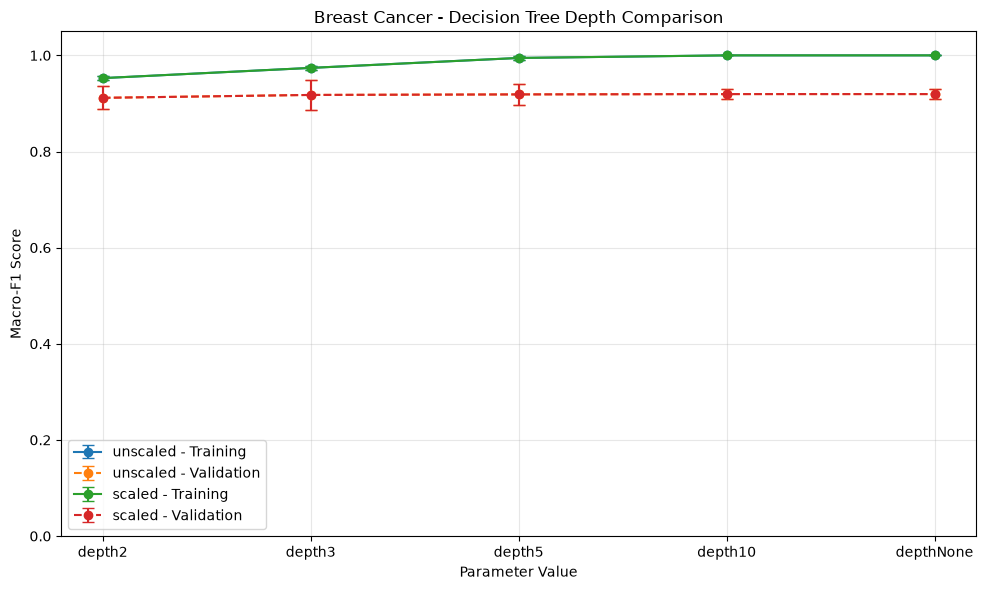

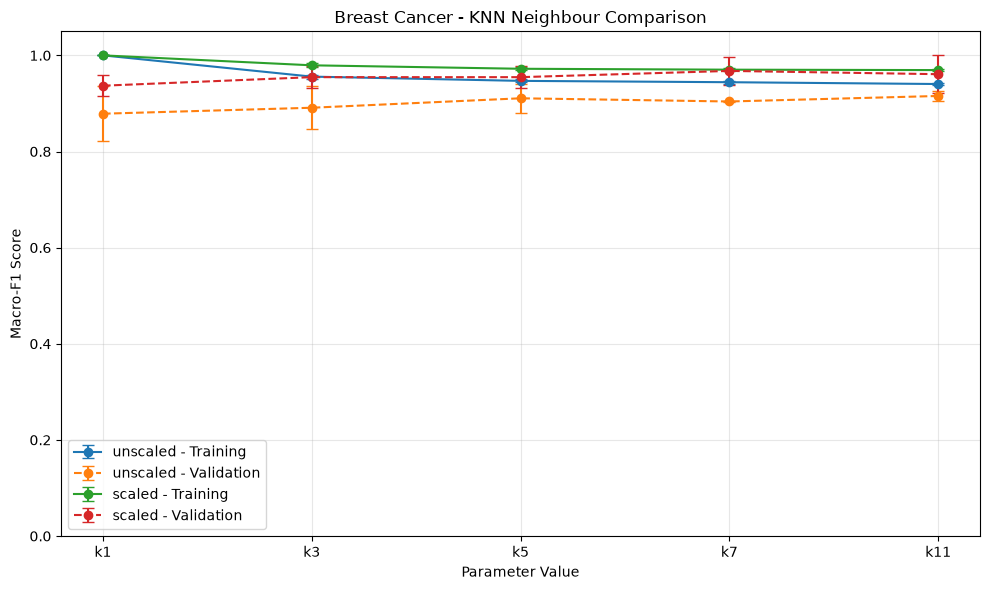

In [212]:

# Parameter comparison plots with seed standard deviations

import matplotlib.pyplot as plt
import numpy as np

def plot_parameter_comparison(algorithm, parameters, title, filename):

    fig, ax = plt.subplots(figsize=(10, 6))

    for representation in ["unscaled", "scaled"]:

        subset = classifier_summary_df[
            (classifier_summary_df["algorithm"] == algorithm) &
            (classifier_summary_df["representation"] == representation)
        ].copy()

        subset["parameter"] = pd.Categorical(
            subset["parameter"],
            categories=parameters,
            ordered=True
        )

        subset = subset.sort_values("parameter")

        x = np.arange(len(subset))

        for metric, linestyle, label in [
            ("train_macro_f1", "-", "Training"),
            ("val_macro_f1", "--", "Validation")
        ]:

            ax.errorbar(
                x,
                subset[f"{metric}_mean"],
                yerr=subset[f"{metric}_std"],
                marker="o",
                linestyle=linestyle,
                capsize=4,
                label=f"{representation} - {label}"
            )

    ax.set_xticks(range(len(parameters)))
    ax.set_xticklabels(parameters)
    ax.set_xlabel("Parameter Value")
    ax.set_ylabel("Macro-F1 Score")
    ax.set_title(title)
    ax.set_ylim(0, 1.05)
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


# Decision Tree depth comparison
plot_parameter_comparison(
    algorithm="decision_tree",
    parameters=["depth2", "depth3", "depth5", "depth10", "depthNone"],
    title="Breast Cancer - Decision Tree Depth Comparison",
    filename="figures/breast_cancer_tree_depth_comparison.png"
)

# KNN neighbour count comparison
plot_parameter_comparison(
    algorithm="knn",
    parameters=["k1", "k3", "k5", "k7", "k11"],
    title="Breast Cancer - KNN Neighbour Comparison",
    filename="figures/breast_cancer_knn_comparison.png"
)




**Interpretation – Classification and Validation**

We trained 66 models using Decision Tree, KNN, and Gaussian Naive Bayes. We used three seeds and both scaled and unscaled data.

We compared the models using validation scores. The best model was scaled KNN with k=7.

Its mean validation macro-F1 score was 0.9677, and the standard deviation was 0.0297.

We selected this model using validation results, not test results.

**Scaling Effect**

KNN was the most affected algorithm by scaling. Its average validation macro-F1 increased by 0.0550.

Decision Tree did not change, and Gaussian Naive Bayes decreased by 0.0121.

**Decision Tree Depth Effect**

The validation macro-F1 increased from 0.9117 at depth 2 to 0.9195 at depth 10.

Depth 10 and unlimited depth gave the same result. Scaling did not change the Decision Tree scores.

This shows that increasing tree depth does not always improve performance.

**KNN Neighbour Count Effect**

The best KNN result was with k=7 using scaled data. Its mean validation macro-F1 was 0.9677.

When k increased to 11, the score decreased to 0.9608.

Scaled KNN performed better than unscaled KNN for all k values. This shows that more neighbours do not always give better results.

**Seed Variability**

The results changed between the three seeds.

For Breast Cancer, the average standard deviation was 0.0236. The minimum was 0.0013, and the maximum was 0.0566.

This shows that different training and validation splits can change model performance.

**Training and Validation Gap**

The training macro-F1 was 0.9702, and the validation macro-F1 was 0.9677.

The gap was only 0.0026. The scores were very close, so there was no large difference between training and validation performance.

# 9. Evaluating the Selected Model on the Test Set
## 9.1 Final Performance Metrics
## 9.2 Confusion Matrix and Manual Metric Calculation
## 9.3 ROC Curve
## 9.4 Error Interpretation

BREAST CANCER - FINAL TEST RESULTS
Selected model: breast_cancer_knn_scaled_k7_s42
Evaluation seed: 42
accuracy: 0.9737
macro_precision: 0.9800
macro_recall: 0.9643
macro_f1: 0.9713
roc_auc: 0.9888

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Malignant       1.00      0.93      0.96        42
      Benign       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



,dataset,selected_configuration,evaluation_seed,mean_val_macro_f1,std_val_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc
0,breast_cancer,breast_cancer_knn_scaled_k7,42,0.9677,0.0297,0.9737,0.98,0.9643,0.9713,0.9888


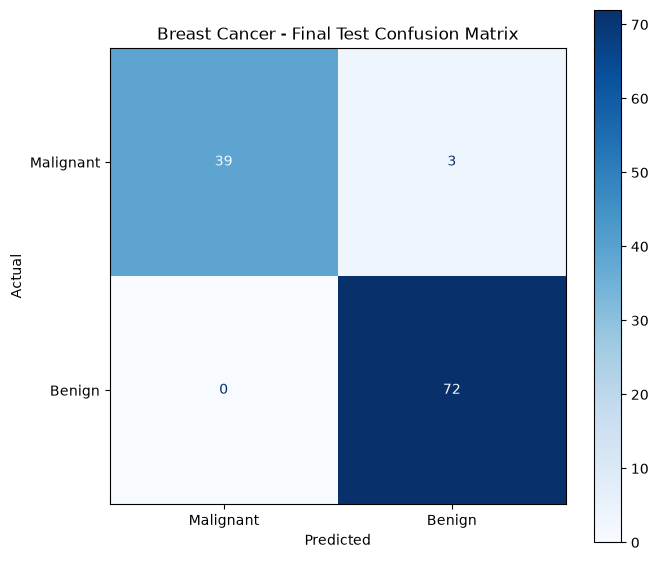


MANUAL CONFUSION MATRIX CHECK
TP: 39
FN: 3
FP: 0
TN: 72
Malignant Precision: 1.0
Malignant Recall: 0.9285714285714286
Malignant F1: 0.962962962962963


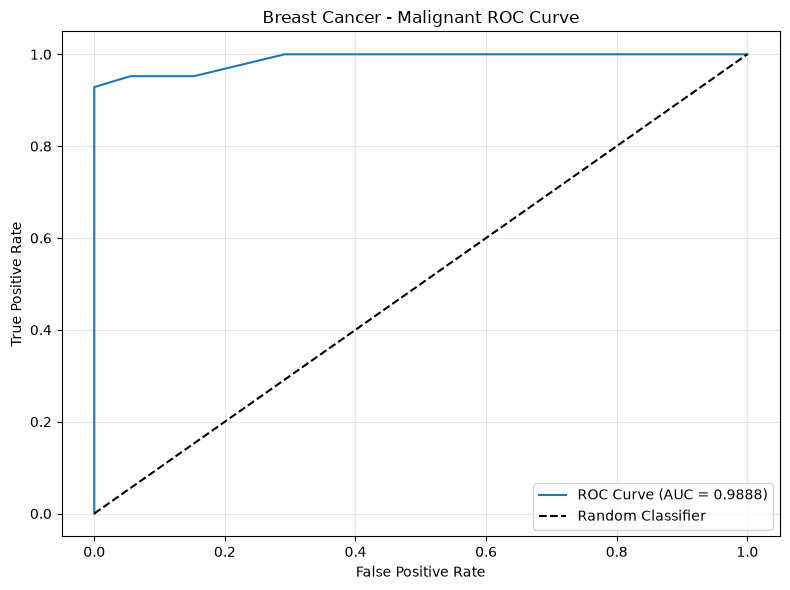


MISCLASSIFIED TEST SAMPLES
Total errors: 3


,actual,predicted
41,0,1
73,0,1
205,0,1



FIRST ERROR - ORIGINAL ROW INDEX: 41


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
41,10.95,21.35,71.9,371.1,0.1227,0.1218,0.1044,0.05669,0.1895,0.0687,...,12.84,35.34,87.22,514.0,0.1909,0.2698,0.4023,0.1424,0.2964,0.09606


In [213]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

# 9.1 Final Test Evaluation
# Use only the selected configuration's seed-42 fitted model

selected_model_id = (
    f"breast_cancer_{best_configuration['algorithm']}_"
    f"{best_configuration['representation']}_"
    f"{best_configuration['parameter']}_s42"
)

selected_model = fitted_models[selected_model_id]

if best_configuration["representation"] == "scaled":
    X_final_test = X_test_scaled
else:
    X_final_test = X_test

# Predict without fitting the model again
y_test_pred = selected_model.predict(X_final_test)
y_test_proba = selected_model.predict_proba(X_final_test)

test_metrics = calculate_metrics(
    y_test,
    y_test_pred,
    y_test_proba,
    selected_model.classes_
)

print("BREAST CANCER - FINAL TEST RESULTS")
print("Selected model:", selected_model_id)
print("Evaluation seed: 42")

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=[0, 1],
        target_names=["Malignant", "Benign"],
        zero_division=0
    )
)

# Save the final test record
classifier_test_df = pd.DataFrame([{
    "dataset": "breast_cancer",
    "selected_configuration": best_configuration["configuration_id"],
    "evaluation_seed": 42,
    "mean_val_macro_f1": best_configuration["val_macro_f1_mean"],
    "std_val_macro_f1": best_configuration["val_macro_f1_std"],
    "test_accuracy": test_metrics["accuracy"],
    "test_macro_precision": test_metrics["macro_precision"],
    "test_macro_recall": test_metrics["macro_recall"],
    "test_macro_f1": test_metrics["macro_f1"],
    "test_roc_auc": test_metrics["roc_auc"]
}])

display(classifier_test_df.round(4))

classifier_test_df.to_csv(
    "results/breast_cancer_classifier_test.csv",
    index=False
)

# 9.2 Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d")

ax.set_title("Breast Cancer - Final Test Confusion Matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig(
    "figures/breast_cancer_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Manual metrics for malignant as positive class
TP = cm[0, 0]
FN = cm[0, 1]
FP = cm[1, 0]
TN = cm[1, 1]

print("\nMANUAL CONFUSION MATRIX CHECK")
print("TP:", TP)
print("FN:", FN)
print("FP:", FP)
print("TN:", TN)

manual_precision = TP / (TP + FP) if TP + FP else np.nan
manual_recall = TP / (TP + FN) if TP + FN else np.nan

manual_f1 = (
    2 * manual_precision * manual_recall /
    (manual_precision + manual_recall)
    if np.isfinite(manual_precision)
    and np.isfinite(manual_recall)
    and manual_precision + manual_recall > 0
    else np.nan
)

print("Malignant Precision:", manual_precision)
print("Malignant Recall:", manual_recall)
print("Malignant F1:", manual_f1)

# 9.3 ROC Curve
malignant_column = list(selected_model.classes_).index(0)
malignant_probabilities = y_test_proba[:, malignant_column]
y_test_binary = (np.asarray(y_test) == 0).astype(int)

fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    malignant_probabilities
)

roc_auc = roc_auc_score(
    y_test_binary,
    malignant_probabilities
)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Breast Cancer - Malignant ROC Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "figures/breast_cancer_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 9.4 Error Analysis
errors = pd.DataFrame({
    "actual": np.asarray(y_test),
    "predicted": y_test_pred
}, index=X_test.index)

errors = errors[
    errors["actual"] != errors["predicted"]
]

print("\nMISCLASSIFIED TEST SAMPLES")
print("Total errors:", len(errors))
display(errors)

if len(errors) > 0:
    first_error_index = errors.index[0]
    print("\nFIRST ERROR - ORIGINAL ROW INDEX:", first_error_index)
    display(X_test.loc[[first_error_index]])
else:
    print("No misclassifications in the fixed test set.")


**Interpretation – Final Test Evaluation**

We tested the selected KNN model with k=7 and scaled data using seed 42.

The test accuracy was 0.9737, macro-F1 was 0.9713, and ROC-AUC was 0.9888.

The model made 111 correct predictions and 3 wrong predictions. It predicted 3 malignant samples as benign. This is an important error because malignant cases were missed.

The test result was close to the mean validation score of 0.9677. However, one test result cannot show that the model will always perform this well.

# 10. K-Means Clustering
## 10.1 Fit the Clustering Model
## 10.2 Final Cluster Evaluation
## 10.3 Cluster Visualisation and Interpretation

K-MEANS RUN RESULTS


,dataset,experiment_id,seed,representation,n_clusters,n_init,train_inertia,val_ari,val_silhouette
0,breast_cancer,breast_cancer_kmeans_unscaled_s42,42,unscaled,2,10,5.156538e+07,0.3995,0.6387
1,breast_cancer,breast_cancer_kmeans_scaled_s42,42,scaled,2,10,7.918810e+03,0.4516,0.2854
2,breast_cancer,breast_cancer_kmeans_unscaled_s52,52,unscaled,2,10,4.919078e+07,0.6122,0.6975
3,breast_cancer,breast_cancer_kmeans_scaled_s52,52,scaled,2,10,8.003001e+03,0.5586,0.3750
4,breast_cancer,breast_cancer_kmeans_unscaled_s62,62,unscaled,2,10,5.305649e+07,0.5013,0.6958
5,breast_cancer,breast_cancer_kmeans_scaled_s62,62,scaled,2,10,7.922515e+03,0.7336,0.2758



K-MEANS SUMMARY


,dataset,representation,inertia_mean,inertia_std,val_ari_mean,val_ari_std,val_silhouette_mean,val_silhouette_std,valid_silhouette_seeds
0,breast_cancer,scaled,7.948109e+03,4.757430e+01,0.5813,0.1424,0.3121,0.0547,3
1,breast_cancer,unscaled,5.127088e+07,1.949607e+06,0.5043,0.1064,0.6773,0.0334,3



TEST RESULTS - UNSCALED
Test ARI: 0.5585
Test Silhouette: 0.712

Cluster Counts
0    86
1    28
Name: count, dtype: int64

CLASS VERSUS CLUSTER TABLE


Cluster ID,0,1
True Class,,
0,14,28
1,72,0


... (2 outputs left out)


FINAL K-MEANS TEST TABLE


,dataset,representation,evaluation_seed,test_cluster_counts,test_ari,test_silhouette
0,breast_cancer,unscaled,42,"{0: 86, 1: 28}",0.5585,0.7120
1,breast_cancer,scaled,42,"{0: 74, 1: 40}",0.7354,0.3251



SELECTED VISUALISATION FEATURES


,mean radius,mean texture
count,398.000000,398.000000
mean,14.111284,19.105980
std,3.556881,4.439559
min,6.981000,9.710000
25%,11.622500,15.870000
50%,13.275000,18.700000
75%,15.745000,21.587500
max,28.110000,39.280000


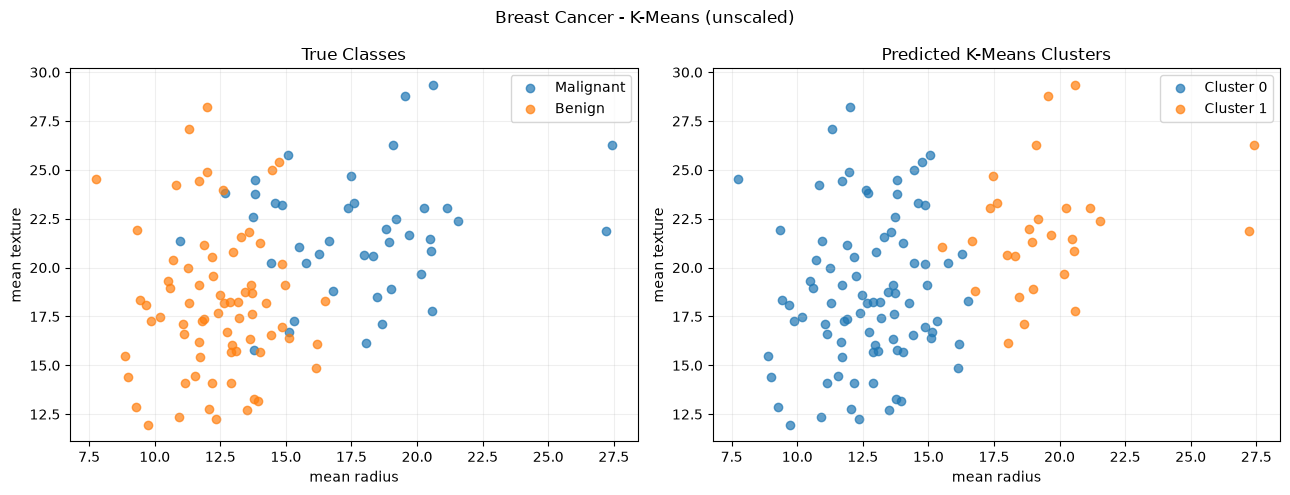

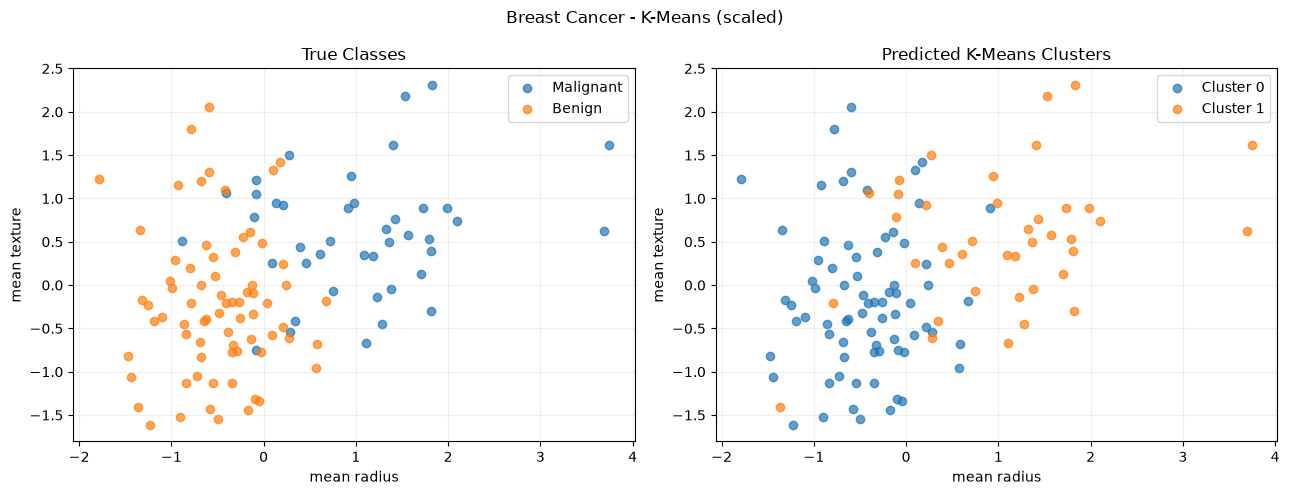

In [214]:

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)

# Store fitted models and results
kmeans_models = {}
kmeans_results = []

def safe_silhouette(features, cluster_labels):
    n_clusters = len(np.unique(cluster_labels))
    if 2 <= n_clusters < len(features):
        return silhouette_score(features, cluster_labels)
    return np.nan

# 10.1 Training and validation
for seed in SEEDS:

    for representation in ["unscaled", "scaled"]:

        data = representations[seed][representation]

        X_train_km = data["X_train"]
        X_val_km = data["X_val"]
        y_val_km = data["y_val"]

        model = KMeans(
            n_clusters=2,
            random_state=seed,
            n_init=10
        )

        # Fit without class labels
        model.fit(X_train_km)

        # Predict validation clusters
        val_clusters = model.predict(X_val_km)

        val_ari = adjusted_rand_score(
            y_val_km, val_clusters
        )

        val_silhouette = safe_silhouette(
            X_val_km, val_clusters
        )

        model_id = f"breast_cancer_kmeans_{representation}_s{seed}"

        kmeans_models[(seed, representation)] = model

        kmeans_results.append({
            "dataset": "breast_cancer",
            "experiment_id": model_id,
            "seed": seed,
            "representation": representation,
            "n_clusters": 2,
            "n_init": 10,
            "train_inertia": model.inertia_,
            "val_ari": val_ari,
            "val_silhouette": val_silhouette
        })

# Six-run table
kmeans_runs_df = pd.DataFrame(kmeans_results)

print("K-MEANS RUN RESULTS")
display(kmeans_runs_df.round(4))

assert len(kmeans_runs_df) == 6

# Summary across seeds
kmeans_summary_df = (
    kmeans_runs_df.groupby(
        ["dataset", "representation"],
        as_index=False
    )
    .agg(
        inertia_mean=("train_inertia", "mean"),
        inertia_std=("train_inertia", "std"),
        val_ari_mean=("val_ari", "mean"),
        val_ari_std=("val_ari", "std"),
        val_silhouette_mean=("val_silhouette", "mean"),
        val_silhouette_std=("val_silhouette", "std"),
        valid_silhouette_seeds=("val_silhouette", "count")
    )
)

print("\nK-MEANS SUMMARY")
display(kmeans_summary_df.round(4))

assert len(kmeans_summary_df) == 2

# Save temporary Breast Cancer results
kmeans_runs_df.to_csv(
    "results/breast_cancer_kmeans_runs.csv",
    index=False
)

kmeans_summary_df.to_csv(
    "results/breast_cancer_kmeans_summary.csv",
    index=False
)


# 10.2 Final test evaluation
kmeans_test_results = []

for representation in ["unscaled", "scaled"]:

    model = kmeans_models[(42, representation)]

    X_test_km = (
        X_test_scaled if representation == "scaled"
        else X_test
    )

    test_clusters = model.predict(X_test_km)

    test_ari = adjusted_rand_score(
        y_test, test_clusters
    )

    test_silhouette = safe_silhouette(
        X_test_km, test_clusters
    )

    cluster_counts = pd.Series(
        test_clusters
    ).value_counts().sort_index()

    print(f"\nTEST RESULTS - {representation.upper()}")
    print("Test ARI:", round(test_ari, 4))
    print("Test Silhouette:", round(test_silhouette, 4)
          if not np.isnan(test_silhouette) else "N/A")

    print("\nCluster Counts")
    print(cluster_counts)

    contingency = pd.crosstab(
        pd.Series(y_test.to_numpy(), name="True Class"),
        pd.Series(test_clusters, name="Cluster ID")
    )

    contingency = contingency.reindex(
        index=[0, 1],
        fill_value=0
    )

    print("\nCLASS VERSUS CLUSTER TABLE")
    display(contingency)

    kmeans_test_results.append({
        "dataset": "breast_cancer",
        "representation": representation,
        "evaluation_seed": 42,
        "test_cluster_counts": str(cluster_counts.to_dict()),
        "test_ari": test_ari,
        "test_silhouette": test_silhouette
    })

kmeans_test_df = pd.DataFrame(kmeans_test_results)

print("\nFINAL K-MEANS TEST TABLE")
display(kmeans_test_df.round(4))

kmeans_test_df.to_csv(
    "results/breast_cancer_kmeans_test.csv",
    index=False
)


# 10.3 Visualisation
# Two original features, inspected from seed-42 training data
selected_features = ["mean radius", "mean texture"]

print("\nSELECTED VISUALISATION FEATURES")
display(
    splits[42]["X_train"][selected_features].describe()
)

for representation in ["unscaled", "scaled"]:

    model = kmeans_models[(42, representation)]

    X_test_km = (
        X_test_scaled if representation == "scaled"
        else X_test
    )

    predicted_clusters = model.predict(X_test_km)

    fig, axes = plt.subplots(
        1, 2, figsize=(13, 5)
    )

    # Panel 1: True classes
    for class_id, class_name in [
        (0, "Malignant"),
        (1, "Benign")
    ]:
        mask = y_test.to_numpy() == class_id

        axes[0].scatter(
            X_test_km.loc[mask, selected_features[0]],
            X_test_km.loc[mask, selected_features[1]],
            label=class_name,
            alpha=0.7
        )

    axes[0].set_title("True Classes")
    axes[0].legend()

    # Panel 2: K-Means clusters
    for cluster_id in np.unique(predicted_clusters):

        mask = predicted_clusters == cluster_id

        axes[1].scatter(
            X_test_km.loc[mask, selected_features[0]],
            X_test_km.loc[mask, selected_features[1]],
            label=f"Cluster {cluster_id}",
            alpha=0.7
        )

    axes[1].set_title("Predicted K-Means Clusters")
    axes[1].legend()

    for ax in axes:
        ax.set_xlabel(selected_features[0])
        ax.set_ylabel(selected_features[1])
        ax.grid(alpha=0.2)

    fig.suptitle(
        f"Breast Cancer - K-Means ({representation})"
    )

    plt.tight_layout()

    plt.savefig(
        f"figures/breast_cancer_kmeans_{representation}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()




**Interpretation – K-Means Clustering**

We trained 6 K-Means models using 3 seeds and both scaled and unscaled data.

The unscaled model had a test ARI of 0.5585 and a silhouette score of 0.7120.

The scaled model had a higher ARI of 0.7354, but a lower silhouette score of 0.3251.

After scaling, the clusters were closer to the real classes. However, some malignant and benign samples were still mixed.

K-Means did not use class labels during training. The silhouette scores were measured on different feature scales, so we cannot compare them directly.